# Data Cleaning and Handling Missing Data with Pandas

Real data is never clean. The NYC taxi data contains trips from 2002, negative fares, trips of zero miles and missing passenger counts. **Data cleaning** finds such problems, decides a rule for each one, applies the rules reproducibly, and reports how many rows each rule affected.

**After this lesson you can:**

1. Profile missing values and decide between dropping, imputing and flagging.
2. Detect invalid values with domain rules (dates, ranges, codes).
3. Detect and remove duplicates.
4. Detect outliers with the IQR rule, and clean categorical codes.
5. Write a reusable cleaning function with a rule-by-rule report.

**Data:** NYC yellow taxi trips, January 2024 (raw, as published by the TLC).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

COLS = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "passenger_count", "trip_distance", "PULocationID", "DOLocationID", "payment_type", "fare_amount", "tip_amount", "total_amount"]
raw = pd.read_parquet(datasets.taxi("2024-01"), columns=COLS)
print(f"{len(raw):,} raw trips")
raw.describe().T[["min", "50%", "max"]]

2,964,624 raw trips


,min,50%,max
tpep_pickup_datetime,2002-12-31 22:59:39,2024-01-17 10:45:37.500000,2024-02-01 00:01:15
tpep_dropoff_datetime,2002-12-31 23:05:41,2024-01-17 11:03:51.500000,2024-02-02 13:56:52
passenger_count,0.0,1.0,9.0
trip_distance,0.0,1.68,312722.3
PULocationID,1.0,162.0,265.0
DOLocationID,1.0,162.0,265.0
payment_type,0.0,1.0,4.0
fare_amount,-899.0,12.8,5000.0
tip_amount,-80.0,2.7,428.0
total_amount,-900.0,20.1,5000.0


The summary already shows problems: negative fares and totals, distances of 0 and of more than 100,000 miles, and pickup dates outside January 2024.

## 1. Missing Values

In [2]:
missing = raw.isna().sum()
print(missing[missing > 0], "\n")
both = raw["passenger_count"].isna()
print("rows with missing passenger_count:", both.sum())
print("payment_type of these rows:", raw.loc[both, "payment_type"].value_counts().to_dict())

passenger_count    140162
dtype: int64 

rows with missing passenger_count: 140162
payment_type of these rows: {0: 140162}


All missing passenger counts belong to `payment_type` 0, a code that is not in the TLC data dictionary (1 = card, 2 = cash, 3 = no charge, 4 = dispute, 5 = unknown, 6 = voided). These rows come from a different recording process. The values are **missing not at random**, so a simple fill would hide a real difference.

| Strategy | When |
| :--- | :--- |
| **drop** rows | few rows, and the missingness does not bias the analysis |
| **impute** (mean, median, group median, model) | the column is needed and missingness is random |
| **flag** (`is_missing` column) + impute | missingness itself carries information |

In [3]:
df = raw.copy()
df["passenger_missing"] = df["passenger_count"].isna()                      # flag
median_by_zone = df.groupby("PULocationID")["passenger_count"].transform("median")
df["passenger_count"] = df["passenger_count"].fillna(median_by_zone).fillna(1)   # group median, then a default
print("missing after imputation:", df["passenger_count"].isna().sum(), "| flagged rows:", df["passenger_missing"].sum())

missing after imputation: 0 | flagged rows: 140162


## 2. Invalid Values: Domain Rules

A value can be present and still wrong. Each rule below comes from domain knowledge about taxi trips. The cell counts how many rows break each rule (a row can break several).

In [4]:
duration_min = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
rules = {
    "pickup outside January 2024": ~df["tpep_pickup_datetime"].between("2024-01-01", "2024-02-01", inclusive="left"),
    "duration < 1 min or > 3 h": ~duration_min.between(1, 180),
    "distance < 0.1 or > 100 miles": ~df["trip_distance"].between(0.1, 100),
    "fare < $3 (the minimum) or > $500": ~df["fare_amount"].between(3, 500),
    "total amount <= 0": df["total_amount"] <= 0,
    "passengers > 6": df["passenger_count"] > 6,
}
report = pd.DataFrame({"rows": {k: int(v.sum()) for k, v in rules.items()}})
report["share_%"] = (100 * report["rows"] / len(df)).round(2)
print(report)
print(f"\nrows breaking at least one rule: {pd.concat(rules, axis=1).any(axis=1).sum():,}")
print("earliest pickup:", df["tpep_pickup_datetime"].min(), "| latest:", df["tpep_pickup_datetime"].max())

                                    rows  share_%
pickup outside January 2024           18     0.00
duration < 1 min or > 3 h          37104     1.25
distance < 0.1 or > 100 miles      69798     2.35
fare < $3 (the minimum) or > $500  39997     1.35
total amount <= 0                  35920     1.21
passengers > 6                        60     0.00

rows breaking at least one rule: 108,866


earliest pickup: 2002-12-31 22:59:39 | latest: 2024-02-01 00:01:15


## 3. Duplicates

In [5]:
key = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID", "trip_distance", "fare_amount"]
dups = df.duplicated(subset=key, keep="first")
print(f"exact duplicates on {len(key)} key columns: {dups.sum():,}")
twin_key = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID"]
refunds = df[df["fare_amount"] < 0]
positive_keys = pd.MultiIndex.from_frame(df.loc[df["fare_amount"] > 0, twin_key])
has_twin = pd.MultiIndex.from_frame(refunds[twin_key]).isin(positive_keys)    # membership test: no row explosion
print(f"negative-fare rows: {len(refunds):,}; with a positive twin at the same time and place: {has_twin.sum():,} "
      f"({has_twin.mean():.0%})")

exact duplicates on 6 key columns: 120


negative-fare rows: 37,448; with a positive twin at the same time and place: 35,378 (94%)


Many negative fares have a positive "twin" with the same pickup time and zone: they are **reversals** of a charge (a correction record), not real trips. Dropping only the negative row would keep the original charge; a finance analysis would need to net them. For trip analysis, the fare rule above removes the reversals.

## 4. Outliers: the IQR Rule

The **interquartile range** rule flags values below $Q_1 - 1.5 \cdot IQR$ or above $Q_3 + 1.5 \cdot IQR$. It is a screening tool, not a verdict: in skewed data such as fares, many flagged values are legitimate (airport trips).

IQR fences: [-9.25, 38.35] -> 282,627 trips flagged (9.9%)
share of flagged trips that start at an airport: 61%


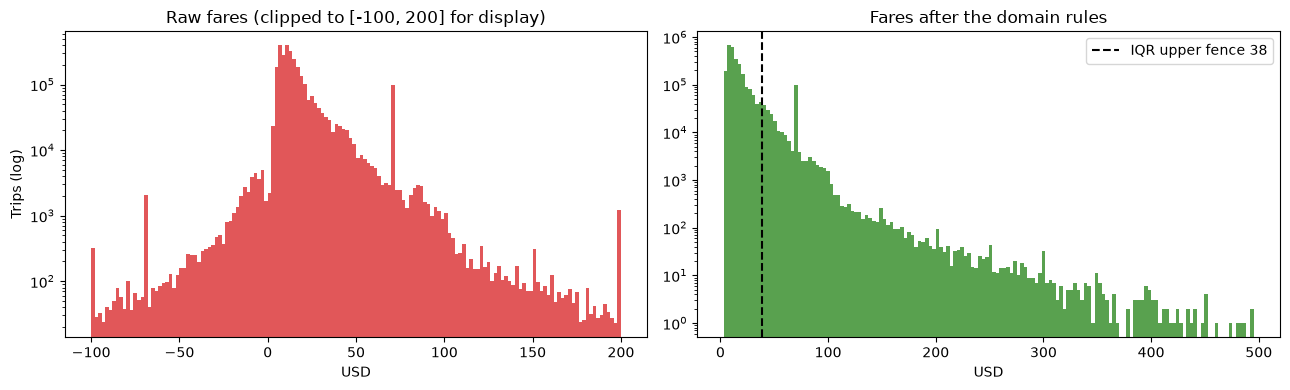

In [6]:
valid = df[~pd.concat(rules, axis=1).any(axis=1)]
q1, q3 = valid["fare_amount"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
flagged = valid[(valid["fare_amount"] < low) | (valid["fare_amount"] > high)]
airport_share = flagged["PULocationID"].isin([1, 132, 138]).mean()
print(f"IQR fences: [{low:.2f}, {high:.2f}] -> {len(flagged):,} trips flagged ({len(flagged) / len(valid):.1%})")
print(f"share of flagged trips that start at an airport: {airport_share:.0%}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.hist(raw["fare_amount"].clip(-100, 200), bins=150, color="#E15759")
ax1.set(yscale="log", title="Raw fares (clipped to [-100, 200] for display)", xlabel="USD", ylabel="Trips (log)")
ax2.hist(valid["fare_amount"], bins=150, color="#59A14F")
ax2.axvline(high, color="black", ls="--", label=f"IQR upper fence {high:.0f}")
ax2.set(yscale="log", title="Fares after the domain rules", xlabel="USD")
ax2.legend()
plt.tight_layout()
plt.show()

## 5. Clean Categorical Codes

Codes need a mapping to readable labels, and unknown codes need a decision. `map` with a dictionary returns `NaN` for codes that are not in the dictionary, which makes unknown codes visible.

In [7]:
PAYMENT = {1: "card", 2: "cash", 3: "no charge", 4: "dispute", 5: "unknown", 6: "voided"}
labels = df["payment_type"].map(PAYMENT)
print("codes without a label:", df.loc[labels.isna(), "payment_type"].value_counts().to_dict())
df["payment"] = labels.fillna("not recorded").astype("category")
print(df["payment"].value_counts())

codes without a label: {0: 140162}
payment
card            2319046
cash             439191
not recorded     140162
dispute           46628
no charge         19597
Name: count, dtype: int64


## 6. A Reusable Cleaning Function

Collect the decisions in one function that returns the clean data **and** a report. The same function runs on every new month of data, and the report shows when a new month behaves differently.

In [8]:
def clean_trips(df: pd.DataFrame, month_start: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Apply the cleaning rules in order; return the clean rows and a report of rows removed per rule."""
    month_end = (pd.Timestamp(month_start) + pd.offsets.MonthBegin(1)).strftime("%Y-%m-%d")
    out = df.copy()
    out["duration_min"] = (out["tpep_dropoff_datetime"] - out["tpep_pickup_datetime"]).dt.total_seconds() / 60
    steps = [
        ("pickup in month", lambda d: d["tpep_pickup_datetime"].between(month_start, month_end, inclusive="left")),
        ("duration 1-180 min", lambda d: d["duration_min"].between(1, 180)),
        ("distance 0.1-100 mi", lambda d: d["trip_distance"].between(0.1, 100)),
        ("fare $3-$500", lambda d: d["fare_amount"].between(3, 500)),
        ("total > 0", lambda d: d["total_amount"] > 0),
        ("no duplicates", lambda d: ~d.duplicated(subset=key)),
    ]
    log = []
    for name, rule in steps:
        before = len(out)
        out = out[rule(out)]
        log.append({"rule": name, "removed": before - len(out), "remaining": len(out)})
    out = out.assign(passenger_missing=out["passenger_count"].isna(),
                     passenger_count=out["passenger_count"].fillna(1).clip(upper=6),
                     payment=out["payment_type"].map(PAYMENT).fillna("not recorded").astype("category"))
    return out.reset_index(drop=True), pd.DataFrame(log)

clean, log = clean_trips(raw, "2024-01-01")
print(log.to_string(index=False))
print(f"\nkept {len(clean) / len(raw):.1%} of the raw rows")
assert clean["fare_amount"].min() >= 3 and clean["duration_min"].between(1, 180).all()

               rule  removed  remaining
    pickup in month       18    2964606
 duration 1-180 min    37104    2927502
distance 0.1-100 mi    38590    2888912
       fare $3-$500    33143    2855769
          total > 0        0    2855769
      no duplicates        0    2855769

kept 96.3% of the raw rows


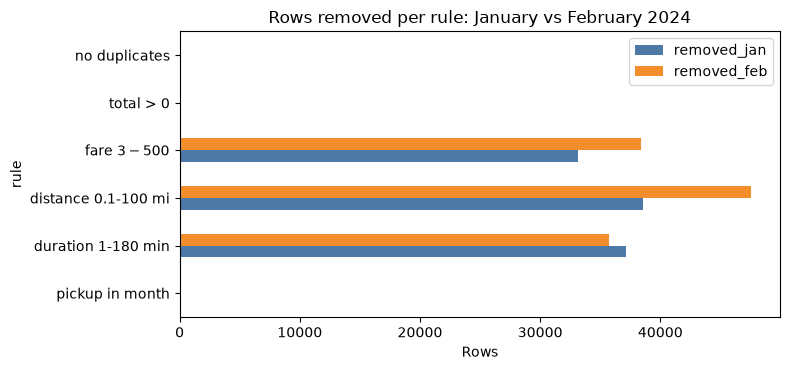

In [9]:
feb, log_feb = clean_trips(pd.read_parquet(datasets.taxi("2024-02"), columns=COLS), "2024-02-01")
compare = log.set_index("rule")[["removed"]].join(log_feb.set_index("rule")[["removed"]], suffixes=("_jan", "_feb"))
compare.plot.barh(figsize=(8, 3.8), color=["#4E79A7", "#F28E2B"], title="Rows removed per rule: January vs February 2024")
plt.xlabel("Rows")
plt.tight_layout()
plt.show()

The same rules remove a similar number of rows in both months, so the February data has no new kind of problem. A sudden change in this chart would be the first sign of a broken upstream system; data-quality tools (Great Expectations, Pandera, dbt tests, M11) automate exactly this kind of check.

*Insight: Turn every cleaning decision into a named rule, apply the rules in one function, and log how many rows each rule removes. Clean data is a result of documented decisions, not of manual edits.*

## Real-World Use Case or Analogy

Data cleaning is like **checking in luggage at an airport**: each rule is a check (weight, size, forbidden items), every bag is checked the same way, and the airline records which bags were rejected and why. Nobody opens bags at random and repacks them by hand.

Studies of data-science work report that cleaning and preparing data takes a large share of project time. Models trained on uncleaned taxi data would learn that some trips cost negative money or last 20 years.